# 05 · Strategy tear sheet
The pre-specified primary strategy: ensemble forecast, value-weighted (capped) decile long-short, net of 25 bps.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from src.utils.config import path
T = path('results') / 'tables'
import pickle
res = pickle.load(open(path('results')/'analysis'/'analysis.pkl','rb')); tear = res['tear']

In [2]:
tear['variants'].set_index('variant').round(4).T

variant,d10_vw,d10_vw_ff12,d10_ew,d10_ew_ff12,q5_vw,q5_vw_ff12,q5_ew,q5_ew_ff12
n_months,137,137,137,137,137,137,137,137
ann_mean,0.0716,0.0678,0.1214,0.1023,0.0651,0.0336,0.0779,0.0574
ann_vol,0.1707,0.1666,0.1574,0.1269,0.1259,0.1147,0.1242,0.1005
sharpe,0.4192,0.4071,0.7716,0.8068,0.5172,0.293,0.6273,0.5711
sortino,0.6486,0.6271,1.2074,1.2752,0.8369,0.4459,0.9778,0.8877
t_mean_nw,1.3137,1.3778,2.6818,2.8128,1.6216,0.9494,2.2137,2.0638
cagr,0.0586,0.0554,0.1147,0.0985,0.0588,0.0274,0.0725,0.0536
max_dd,-0.3765,-0.3536,-0.2298,-0.2806,-0.2413,-0.2738,-0.2514,-0.2345
calmar,0.1557,0.1567,0.4991,0.3511,0.2438,0.1001,0.2886,0.2287
hit_rate,0.5474,0.5693,0.6642,0.635,0.562,0.4891,0.6131,0.5912


In [3]:
tear['alphas'].round(4)

,model,alpha_m,alpha_ann,t_alpha,r2_adj,n,b_mktrf,t_mktrf,b_smb,t_smb,b_hml,t_hml,b_rmw,t_rmw,b_cma,t_cma,b_mom,t_mom,b_lowvol,t_lowvol,series
0,CAPM,0.0030,0.0365,0.6932,0.0318,137,-0.2193,-1.8977,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,LS net 25bps
1,FF3,-0.0011,-0.0131,-0.3180,0.2859,137,-0.0376,-0.3736,-0.8509,-5.1245,-0.1040,-0.9298,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,LS net 25bps
2,FF5,-0.0022,-0.0268,-0.6699,0.3276,137,-0.0993,-1.0530,-0.6394,-3.7476,-0.1490,-1.0803,0.6127,2.8664,-0.1391,-0.8877,NaN,NaN,NaN,NaN,LS net 25bps
3,FF5+Mom,-0.0036,-0.0427,-1.0043,0.3675,137,-0.0334,-0.3626,-0.5231,-2.8755,-0.0399,-0.3081,0.7152,3.2817,-0.2376,-1.5516,0.3196,2.1908,NaN,NaN,LS net 25bps
4,FF5+Mom+LowVol,-0.0042,-0.0500,-1.2508,0.4405,137,0.1327,1.5078,-0.2101,-1.1679,-0.1989,-1.4834,0.3071,1.3969,-0.1488,-0.9066,0.2906,2.3585,0.2760,5.1661,LS net 25bps
0,CAPM,0.0080,0.0961,1.8166,0.0314,137,-0.2179,-1.8879,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,LS gross
1,FF3,0.0039,0.0466,1.1226,0.2855,137,-0.0367,-0.3628,-0.8491,-5.1069,-0.1058,-0.9412,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,LS gross
2,FF5,0.0027,0.0328,0.8143,0.3274,137,-0.0982,-1.0335,-0.6369,-3.7409,-0.1520,-1.1078,0.6137,2.8897,-0.1367,-0.8745,NaN,NaN,NaN,NaN,LS gross
3,FF5+Mom,0.0014,0.0169,0.3934,0.3679,137,-0.0320,-0.3453,-0.5200,-2.8593,-0.0424,-0.3308,0.7166,3.3063,-0.2357,-1.5521,0.3211,2.2039,NaN,NaN,LS gross
4,FF5+Mom+LowVol,0.0008,0.0096,0.2388,0.4405,137,0.1335,1.5083,-0.2082,-1.1606,-0.2008,-1.5128,0.3101,1.4165,-0.1472,-0.9045,0.2922,2.3706,0.2751,5.1687,LS gross


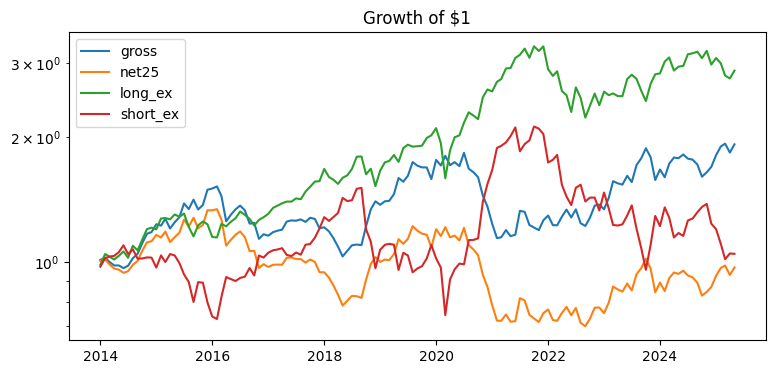

In [4]:
s = tear['series']['d10_vw']
fig, ax = plt.subplots(figsize=(9,4))
for k in ['gross','net25','long_ex','short_ex']: ax.plot(s[k].index.to_timestamp(), (1+s[k].fillna(0)).cumprod(), label=k)
ax.set_yscale('log'); ax.legend(); ax.set_title('Growth of $1'); plt.show()

In [5]:
res['subperiods'].round(3)

,period,months,ann_mean,sharpe,t_mean,alpha_ann,t_alpha
0,2014-2017,48,-0.004,-0.027,-0.055,-0.032,-0.724
1,2018-2021,48,-0.038,-0.197,-0.318,-0.044,-0.581
2,2020 (COVID),12,-0.194,-0.867,-0.868,NaN,NaN
3,test 2022-01 to 2025-05,41,0.089,0.515,1.457,-0.046,-0.830
